# 02 - Modeling and experiments

Goal: predict **podium / no podium** for each driver in each race, from the table made in notebook 01.

What is in here:

1. Load the modeling table and split it
2. A look at the features
3. Pre-processing (missing values, scaling)
4. Metrics and the baseline
5. Statistical models: logistic regression, random forest, gradient boosting
6. Shallow neural network
7. Model comparison on the test set
8. Experiments: feature-group ablation, grid encoding, training years, pre-processing order
9. Explainability: permutation importance, SHAP, LIME
10. Inference function

## 1. Load and split

`DATA_DIR` is the only path to change on Kaggle.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow info messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, precision_recall_curve
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

import keras
from keras import layers
import shap
from lime.lime_tabular import LimeTabularExplainer

DATA_DIR = '../../data/processed'   # on Kaggle: '/kaggle/working'

In [2]:
df = pd.read_csv(DATA_DIR + '/modeling_table.csv')
df.shape

(24571, 33)

In [3]:
df.head()

,raceId,driverId,constructorId,circuitId,year,round,date,split,podium,grid_position,...,constructor_mechanical_retirement_rate_last_10_races,driver_points_share_before_race,driver_standing_position_before_race,driver_season_wins_before_race,constructor_points_share_before_race,constructor_standing_position_before_race,driver_age,home_race,season_progress,circuit_podium_rate_for_grid_group
0,833,642,51,9,1950,1,1950-05-13,train,1,1,...,NaN,0.0,NaN,0.0,NaN,NaN,43.534565,0,0.142857,NaN
1,833,786,51,9,1950,1,1950-05-13,train,1,2,...,NaN,0.0,NaN,0.0,NaN,NaN,51.923340,0,0.142857,NaN
2,833,686,51,9,1950,1,1950-05-13,train,1,4,...,NaN,0.0,NaN,0.0,NaN,NaN,38.863792,1,0.142857,NaN
3,833,704,154,9,1950,1,1950-05-13,train,0,6,...,NaN,0.0,NaN,0.0,NaN,NaN,45.593429,0,0.142857,NaN
4,833,627,154,9,1950,1,1950-05-13,train,0,9,...,NaN,0.0,NaN,0.0,NaN,NaN,44.517454,0,0.142857,NaN


The first 8 columns are keys, `podium` is the target, and the other 24 columns are the features. All 24 features are numbers already, so nothing needs encoding.

In [4]:
keys = ['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'date', 'split']
features = [c for c in df.columns if c not in keys + ['podium']]

print(len(features))
df[features].dtypes.value_counts()

24


float64    19
int64       5
Name: count, dtype: int64

The grain must be one row per driver per race. We check it before modeling.

In [5]:
df.duplicated(['raceId', 'driverId']).sum()

np.int64(0)

### The split

Notebook 01 saved a `split` column: train up to 2019, validation 2020-2021, test 2022-2024.

We split **by season and not at random** for two reasons:

- At prediction time we only know the past. A random split would train on 2023 races and test on 2021 races.
- The form and standings features of one race are built from the races before it. With a random split, neighbouring races would sit on both sides.

In [6]:
df.groupby('split')['year'].agg(['min', 'max', 'count'])

,min,max,count
split,,,
test,2022,2024,1352
train,1950,2019,22444
val,2020,2021,775


In [7]:
df.groupby('split')['podium'].mean().round(3)

split
test     0.151
train    0.135
val      0.151
Name: podium, dtype: float64

About 14-15% of the rows are podiums in every split, so the classes are **imbalanced**. A model that always says "no podium" would be right 86% of the time, so accuracy is not a useful metric here (see section 4).

In [8]:
train = df[df['split'] == 'train']
val = df[df['split'] == 'val']
test = df[df['split'] == 'test']

y_train = train['podium']
y_val = val['podium']
y_test = test['podium']

print(train.shape, val.shape, test.shape)

(22444, 33) (775, 33) (1352, 33)


## 2. A look at the features

Notebook 01 explains how every feature is built and why it is known before the race. Here we look at what they can do for the model. We only look at the **training rows**, so the validation and test sets stay unseen.

### 2.1 Each feature against the target

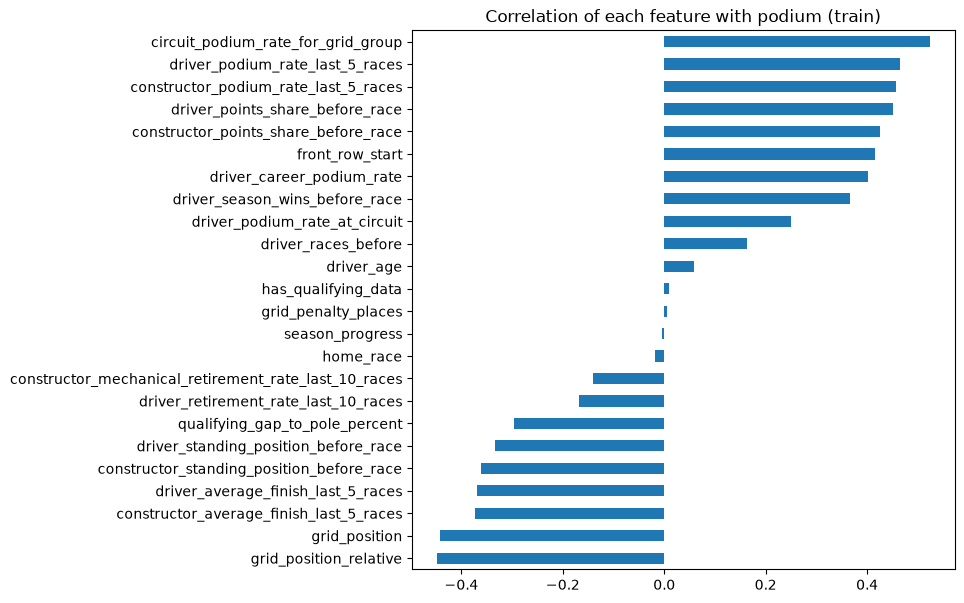

In [9]:
train[features].corrwith(y_train).sort_values().plot(kind='barh', figsize=(7, 7), title='Correlation of each feature with podium (train)')
plt.show()

The grid features, the recent form of driver and team, and the standings are the strongest. `home_race`, `season_progress`, `grid_penalty_places` and `has_qualifying_data` are close to 0 on their own. We keep them anyway and let the ablation in section 8 measure them, because a feature can be weak alone and still help next to others.

The start position is the most direct signal, so we look at it on its own.

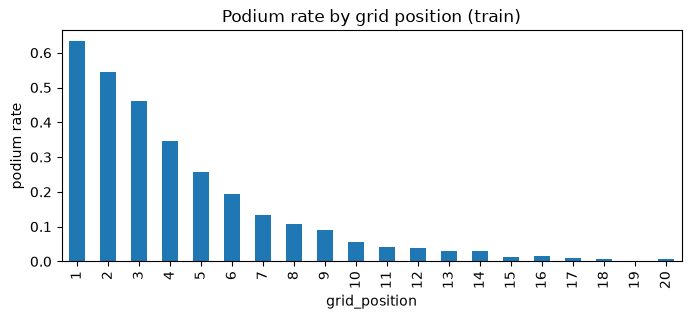

In [10]:
train[train['grid_position'] <= 20].groupby('grid_position')['podium'].mean().plot(kind='bar', figsize=(8, 3), title='Podium rate by grid position (train)')
plt.ylabel('podium rate')
plt.show()

The podium rate falls fast with the grid position and it is not a straight line. This is why we keep `front_row_start` and `circuit_podium_rate_for_grid_group` next to the raw grid position: they help a linear model with the curve.

### 2.2 Features against each other

Two features that say the same thing do not hurt the predictions much, but they make importances harder to read.

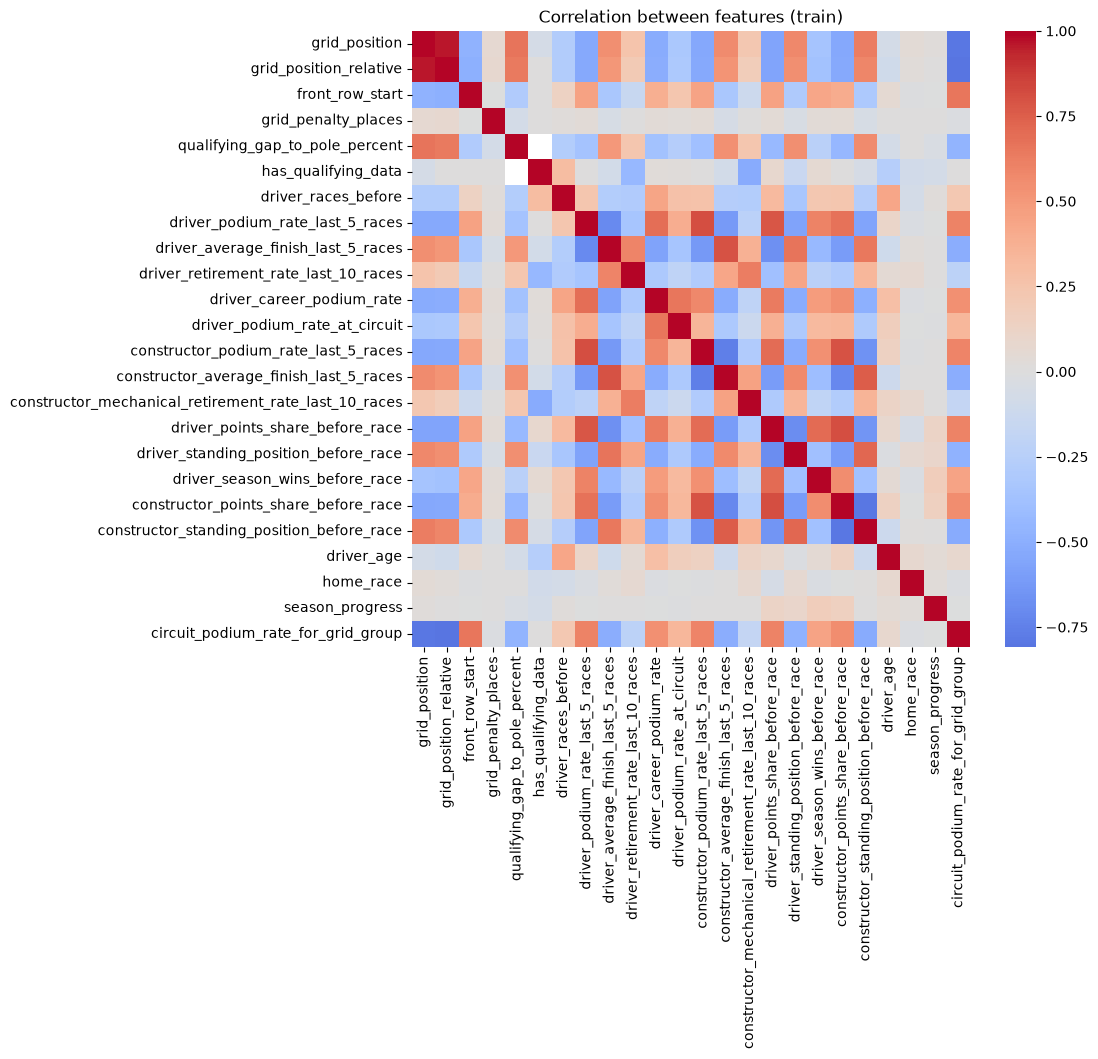

In [11]:
corr = train[features].corr()

plt.figure(figsize=(9, 8))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation between features (train)')
plt.show()

In [12]:
# keep each pair once (upper triangle), then list the strong ones
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pairs[pairs.abs() > 0.8].round(2)

grid_position                    grid_position_relative                  0.96
grid_position_relative           circuit_podium_rate_for_grid_group     -0.81
driver_podium_rate_last_5_races  constructor_podium_rate_last_5_races    0.81
driver_points_share_before_race  constructor_points_share_before_race    0.81
dtype: float64

Four pairs are above 0.8:

- `grid_position` and `grid_position_relative` (0.96) are almost the same number. Section 8.2 tests whether we need both.
- `circuit_podium_rate_for_grid_group` is built from the grid group, so it follows the grid.
- Driver and constructor form (and driver and constructor points) move together, because a driver's results are also his team's results.

So the groups overlap. We should expect that removing one group costs little, since another group can stand in for it.

## 3. Pre-processing

### 3.1 Missing values

Notebook 01 left the missing values empty on purpose. We count them per split.

In [13]:
missing = pd.DataFrame({'train': train[features].isna().sum(), 'val': val[features].isna().sum(), 'test': test[features].isna().sum()})
missing[missing['train'] > 0]

,train,val,test
qualifying_gap_to_pole_percent,14284,9,13
driver_podium_rate_last_5_races,667,6,8
driver_average_finish_last_5_races,667,6,8
driver_retirement_rate_last_10_races,667,6,8
driver_career_podium_rate,667,6,8
driver_podium_rate_at_circuit,7058,218,168
constructor_podium_rate_last_5_races,256,4,2
constructor_average_finish_last_5_races,256,4,2
constructor_mechanical_retirement_rate_last_10_races,256,4,2
driver_standing_position_before_race,2778,43,68


13 features have missing values. The big one is `qualifying_gap_to_pole_percent`: empty in 14,284 training rows (no lap times in the old seasons) but almost complete in validation and test.

We fill every missing value with the **median of the training rows**. Median and not mean, because several of these features are skewed. The medians are learned from train only and reused for validation and test, so no information flows back from the later seasons.

In [14]:
medians = train[features].median()

X_train = train[features].fillna(medians)
X_val = val[features].fillna(medians)
X_test = test[features].fillna(medians)

print(X_train.isna().sum().sum(), X_val.isna().sum().sum(), X_test.isna().sum().sum())

0 0 0


No missing values are left. Now the effect on the feature that was filled the most.

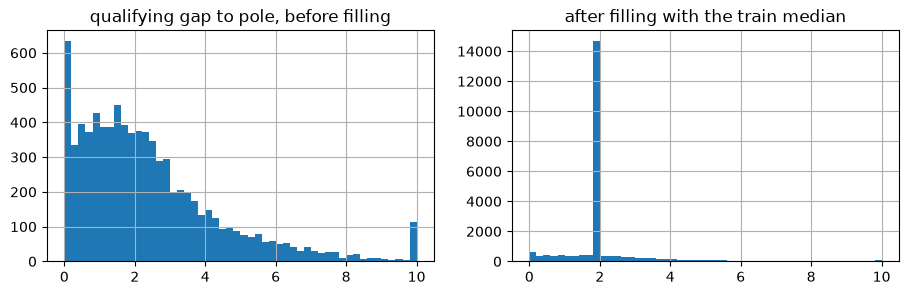

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
train['qualifying_gap_to_pole_percent'].clip(upper=10).hist(bins=50, ax=ax[0])
ax[0].set_title('qualifying gap to pole, before filling')
X_train['qualifying_gap_to_pole_percent'].clip(upper=10).hist(bins=50, ax=ax[1])
ax[1].set_title('after filling with the train median')
plt.show()

Filling puts 14,284 rows on one value, so the feature now has a tall spike at the median. For those rows it carries no information, which is fine: `has_qualifying_data` tells the model which races had qualifying data. We test adding more "was missing" flags in section 8.

### 3.2 Scaling

The features have very different ranges.

In [16]:
X_train.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
grid_position,11.91,6.81,1.00,34.0
grid_position_relative,0.52,0.29,0.03,1.0
front_row_start,0.09,0.28,0.00,1.0
grid_penalty_places,-0.00,0.85,-9.00,23.0
qualifying_gap_to_pole_percent,2.16,1.57,0.00,37.8
has_qualifying_data,0.37,0.48,0.00,1.0
driver_races_before,61.45,61.59,0.00,321.0
driver_podium_rate_last_5_races,0.13,0.23,0.00,1.0
driver_average_finish_last_5_races,11.75,4.36,1.00,31.0
driver_retirement_rate_last_10_races,0.42,0.25,0.00,1.0


`driver_races_before` goes up to a few hundred while the rates stay between 0 and 1. Logistic regression (with its penalty) and the neural network both work better when the features are on the same scale, so we standardise: subtract the mean and divide by the standard deviation.

The mean and standard deviation come from the **training rows only**, like the medians.

In [17]:
mean = X_train.mean()
std = X_train.std()

X_train_s = (X_train - mean) / std
X_val_s = (X_val - mean) / std
X_test_s = (X_test - mean) / std

X_train_s.describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
grid_position,-0.0,1.0,-1.60,3.24
grid_position_relative,-0.0,1.0,-1.71,1.66
front_row_start,-0.0,1.0,-0.31,3.20
grid_penalty_places,0.0,1.0,-10.59,27.07
qualifying_gap_to_pole_percent,-0.0,1.0,-1.37,22.66
has_qualifying_data,-0.0,1.0,-0.77,1.30
driver_races_before,-0.0,1.0,-1.00,4.21
driver_podium_rate_last_5_races,0.0,1.0,-0.57,3.71
driver_average_finish_last_5_races,0.0,1.0,-2.47,4.42
driver_retirement_rate_last_10_races,0.0,1.0,-1.69,2.38


Every feature now has mean 0 and standard deviation 1 on train. The shape of each distribution is the same as before, only the axis changed.

Tree models split on thresholds, so scaling changes nothing for them. They get the filled, unscaled table (`X_train`), which keeps their plots in real units. Logistic regression and the neural network get the scaled table (`X_train_s`). All models use the **same rows, the same 24 features and the same filled values**.

## 4. Metrics and the baseline

We report five metrics for every model:

| Metric | What it tells us |
|---|---|
| ROC-AUC | How well the model ranks podium rows above the others, over all thresholds. |
| PR-AUC | The same, but it only looks at precision and recall of the podium class. |
| F1 | Balance of precision and recall at one threshold. |
| Precision | Of the rows we call podium, how many are. |
| Recall | Of the real podiums, how many we find. |

- **Primary metric: PR-AUC.** Only 14% of the rows are podiums. ROC-AUC also rewards the model for the many easy "no podium" rows at the back of the grid, so it looks high for every model. PR-AUC only moves when the podium rows are ranked better.
- **Secondary metric: ROC-AUC**, to compare with other work, and **F1** for the final yes/no decision.

F1, precision and recall need a threshold. The default 0.5 is a poor choice with rare positives, so for each model we take the threshold with the **best F1 on the validation set**. The test set is never used for this.

These steps are the same for every model, so they go in three small functions.

In [18]:
results = []      # one row per model and split
thresholds = {}   # the chosen threshold of each model
cols = ['model', 'split', 'roc_auc', 'pr_auc', 'f1', 'precision', 'recall']

def best_threshold(y, p):
    # the threshold with the highest F1
    precision, recall, cuts = precision_recall_curve(y, p)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return cuts[f1[:-1].argmax()]

def add_scores(name, split, y, p):
    pred = (p >= thresholds[name]).astype(int)
    results.append([name, split, roc_auc_score(y, p), average_precision_score(y, p), f1_score(y, pred), precision_score(y, pred), recall_score(y, pred)])

def evaluate(name, p_train, p_val):
    # pick the threshold on validation, then score train and validation
    thresholds[name] = best_threshold(y_val, p_val)
    add_scores(name, 'train', y_train, p_train)
    add_scores(name, 'val', y_val, p_val)
    return pd.DataFrame(results[-2:], columns=cols).round(3)

### 4.1 Baseline without a model: the grid rule

The simplest idea is "the cars at the front finish at the front". We use `1 / grid_position` as the score, so pole gets 1, second gets 0.5, and so on. Any model must beat this to be worth training.

In [19]:
evaluate('Grid rule', 1 / train['grid_position'], 1 / val['grid_position'])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Grid rule,train,0.883,0.500,0.544,0.547,0.541
1,Grid rule,val,0.910,0.648,0.695,0.698,0.692


In [20]:
1 / thresholds['Grid rule']

np.float64(3.0)

The best threshold is `grid_position <= 3`: "the top 3 on the grid are the podium". This rule alone already gets a PR-AUC of 0.65 and an F1 of 0.70 on validation. That is the bar for every model below.

The scores are higher on validation than on train. This will be true for every model: the training rows go back to 1950, when races were less predictable (more retirements, bigger fields), and the validation rows are modern races.

## 5. Statistical models

### 5.1 Logistic regression (the baseline model)

**How it works:** it multiplies each feature by a weight, adds them up, and squeezes the sum into a probability between 0 and 1. Training finds the weights.

**Limits:** each feature can only push the probability up or down in one direction, and features cannot interact unless we build the interaction ourselves.

It is the simplest reasonable model for a yes/no target, so it is our baseline. First with the default settings.

In [21]:
lr = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)

evaluate('Logistic regression', lr.predict_proba(X_train_s)[:, 1], lr.predict_proba(X_val_s)[:, 1])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Logistic regression,train,0.901,0.578,0.585,0.481,0.748
1,Logistic regression,val,0.931,0.746,0.713,0.646,0.795


The main setting is `C`, the strength of the penalty on the weights (small `C` = strong penalty). We try four values and compare PR-AUC on validation.

In [22]:
rows = []
for C in [0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C, max_iter=1000).fit(X_train_s, y_train)
    rows.append([C, average_precision_score(y_train, m.predict_proba(X_train_s)[:, 1]), average_precision_score(y_val, m.predict_proba(X_val_s)[:, 1])])

pd.DataFrame(rows, columns=['C', 'train_pr_auc', 'val_pr_auc']).round(4)

,C,train_pr_auc,val_pr_auc
0,0.01,0.5764,0.7477
1,0.10,0.5772,0.7470
2,1.00,0.5776,0.7459
3,10.00,0.5776,0.7459


With the default settings the logistic regression reaches a PR-AUC of 0.746 on validation, against 0.648 for the grid rule. Train and validation move together, so it does not overfit.

`C` changes almost nothing: the four values are within 0.002 of each other on validation. That is far too small to mean anything with 117 validation podiums, so we keep the default `C = 1`.

### 5.2 Random forest

**How it works:** it grows many decision trees, each on a random sample of the rows and with a random choice of features at every split, and averages their votes.

**Why try it:** trees handle curves and interactions on their own (for example "front of the grid **and** a strong team").

**Limits:** deep trees memorise the training rows, and a forest cannot predict outside what it has seen.

First with the default settings (300 trees so the result is stable).

In [23]:
rf_default = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train)

print('train PR-AUC:', round(average_precision_score(y_train, rf_default.predict_proba(X_train)[:, 1]), 3))
print('val PR-AUC:  ', round(average_precision_score(y_val, rf_default.predict_proba(X_val)[:, 1]), 3))

train PR-AUC: 1.0
val PR-AUC:   0.685


The default forest is perfect on train and clearly worse on validation: it **overfits**. The default trees grow until every leaf is pure. We limit the depth and look again.

In [24]:
rows = []
for depth in [3, 5, 10, None]:
    m = RandomForestClassifier(n_estimators=300, max_depth=depth, random_state=42, n_jobs=-1).fit(X_train, y_train)
    rows.append([depth, average_precision_score(y_train, m.predict_proba(X_train)[:, 1]), average_precision_score(y_val, m.predict_proba(X_val)[:, 1])])

pd.DataFrame(rows, columns=['max_depth', 'train_pr_auc', 'val_pr_auc']).round(4)

,max_depth,train_pr_auc,val_pr_auc
0,3.0,0.5874,0.7330
1,5.0,0.6119,0.7324
2,10.0,0.8401,0.7008
3,NaN,1.0000,0.6850


The shallower the trees, the lower the train score and the **higher** the validation score. Depth 3 and depth 5 are the same on validation (0.733 and 0.732) and both are clearly better than the default (0.685). We take `max_depth = 5`.

In [25]:
rf = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42, n_jobs=-1).fit(X_train, y_train)

evaluate('Random forest', rf.predict_proba(X_train)[:, 1], rf.predict_proba(X_val)[:, 1])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Random forest,train,0.909,0.612,0.599,0.511,0.724
1,Random forest,val,0.932,0.732,0.716,0.657,0.786


### 5.3 Gradient boosting

**How it works:** it also uses trees, but builds them one after the other. Each new small tree corrects the mistakes of the trees before it.

**Limits:** more settings to tune than a forest, and with too many trees it starts to fit noise.

We try a few sizes. The first row is the default.

In [26]:
rows = []
for n, depth in [(100, 3), (100, 2), (300, 2), (300, 3)]:
    m = GradientBoostingClassifier(n_estimators=n, max_depth=depth, random_state=42).fit(X_train, y_train)
    rows.append([n, depth, average_precision_score(y_train, m.predict_proba(X_train)[:, 1]), average_precision_score(y_val, m.predict_proba(X_val)[:, 1])])

pd.DataFrame(rows, columns=['n_estimators', 'max_depth', 'train_pr_auc', 'val_pr_auc']).round(4)

,n_estimators,max_depth,train_pr_auc,val_pr_auc
0,100,3,0.6568,0.7244
1,100,2,0.6121,0.7122
2,300,2,0.6532,0.7207
3,300,3,0.7358,0.7153


The default (100 trees of depth 3) is the best on validation. More trees raise the train score but not the validation score, which is overfitting again. We keep the default.

In [27]:
gb = GradientBoostingClassifier(random_state=42).fit(X_train, y_train)

evaluate('Gradient boosting', gb.predict_proba(X_train)[:, 1], gb.predict_proba(X_val)[:, 1])

,model,split,roc_auc,pr_auc,f1,precision,recall
0,Gradient boosting,train,0.916,0.657,0.613,0.539,0.712
1,Gradient boosting,val,0.928,0.724,0.725,0.707,0.744


## 6. Shallow neural network

**How it works:** each hidden unit is a small logistic regression. A hidden layer has several of them, and the output unit combines them into one probability. With no hidden layer the network would be exactly a logistic regression.

**Limits:** the result changes with the random start, it needs scaled inputs, and it is harder to explain than a list of weights.

We use Keras. The training steps are the same for every network we try, so they go in one function:

- `relu` hidden layers and one `sigmoid` output, because the target is yes/no
- `binary_crossentropy` loss with the `adam` optimiser (the standard pair for this)
- **early stopping**: training stops when the validation loss has not improved for 10 epochs, and the best weights are kept. This picks the number of epochs for us and limits overfitting.
- a fixed seed so Run All gives the same result

In [28]:
def train_nn(hidden, dropout, seed):
    keras.utils.set_random_seed(seed)
    nn = keras.Sequential([keras.Input(shape=(len(features),))])
    for units in hidden:
        nn.add(layers.Dense(units, activation='relu'))
        nn.add(layers.Dropout(dropout))
    nn.add(layers.Dense(1, activation='sigmoid'))
    nn.compile(optimizer='adam', loss='binary_crossentropy')
    stop = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
    history = nn.fit(X_train_s, y_train, validation_data=(X_val_s, y_val), epochs=100, batch_size=64, verbose=0, callbacks=[stop])
    return nn, history

### 6.1 One hidden layer

The smallest network: one hidden layer with 16 units and no dropout.

In [29]:
nn1, history1 = train_nn([16], 0, 42)
nn1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,253 (4.90 KB)

 Trainable params: 417 (1.63 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 836 (3.27 KB)

In [30]:
evaluate('NN 1 layer (16)', nn1.predict(X_train_s, verbose=0).ravel(), nn1.predict(X_val_s, verbose=0).ravel())

,model,split,roc_auc,pr_auc,f1,precision,recall
0,NN 1 layer (16),train,0.909,0.601,0.591,0.486,0.752
1,NN 1 layer (16),val,0.930,0.727,0.723,0.682,0.769


### 6.2 Two hidden layers with dropout

A bit bigger: 32 and 16 units. A bigger network overfits more easily, so we add dropout of 0.2 (during training, 20% of the units are switched off at random in each step).

In [31]:
nn2, history2 = train_nn([32, 16], 0.2, 42)

evaluate('NN 2 layers (32-16)', nn2.predict(X_train_s, verbose=0).ravel(), nn2.predict(X_val_s, verbose=0).ravel())

,model,split,roc_auc,pr_auc,f1,precision,recall
0,NN 2 layers (32-16),train,0.909,0.600,0.599,0.510,0.726
1,NN 2 layers (32-16),val,0.931,0.751,0.713,0.677,0.752


The loss per epoch for both networks.

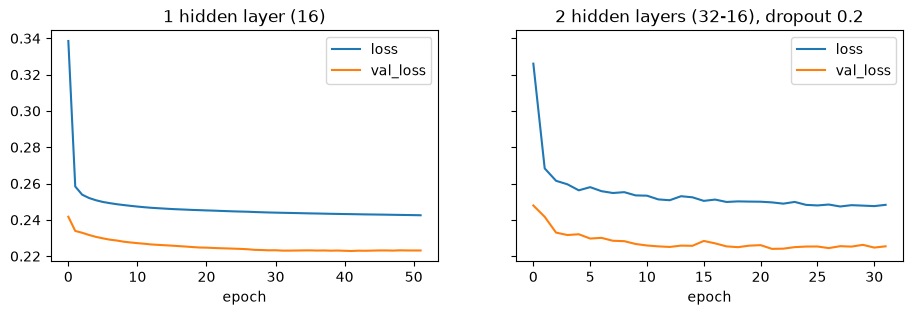

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
pd.DataFrame(history1.history).plot(ax=ax[0], title='1 hidden layer (16)')
pd.DataFrame(history2.history).plot(ax=ax[1], title='2 hidden layers (32-16), dropout 0.2')
ax[0].set_xlabel('epoch')
ax[1].set_xlabel('epoch')
plt.show()

Both networks stop on their own after 30 to 50 epochs, and the train and validation curves stay flat next to each other, so there is no sign of overfitting. The validation loss is **below** the train loss for the same reason as before: the modern validation races are easier to predict than the full 1950-2019 training set.

The two-layer network scores a little higher on validation PR-AUC (0.751 against 0.727).

### 6.3 How much does the random start matter?

A network starts from random weights. We train the two-layer network again with three other seeds to see how far the validation score moves from the seed alone.

In [33]:
rows = []
for seed in [1, 2, 3]:
    m, h = train_nn([32, 16], 0.2, seed)
    p = m.predict(X_val_s, verbose=0).ravel()
    rows.append([seed, roc_auc_score(y_val, p), average_precision_score(y_val, p)])

pd.DataFrame(rows, columns=['seed', 'val_roc_auc', 'val_pr_auc']).round(4)

,seed,val_roc_auc,val_pr_auc
0,1,0.9285,0.7438
1,2,0.9306,0.7497
2,3,0.9310,0.7469


With the same data and the same network, the validation PR-AUC moves between about 0.744 and 0.751 just from the random start. On another machine the numbers can shift by a similar amount.

This gives us a feel for the noise: **a difference of less than about 0.01 in validation PR-AUC between two models is not a real difference.**

## 7. Model comparison

Everything so far was chosen with train and validation only. Now we score the final version of each model on the test set (2022-2024), **once**, with the thresholds picked on validation.

In [34]:
p_test = {
    'Grid rule': 1 / test['grid_position'],
    'Logistic regression': lr.predict_proba(X_test_s)[:, 1],
    'Random forest': rf.predict_proba(X_test)[:, 1],
    'Gradient boosting': gb.predict_proba(X_test)[:, 1],
    'NN 1 layer (16)': nn1.predict(X_test_s, verbose=0).ravel(),
    'NN 2 layers (32-16)': nn2.predict(X_test_s, verbose=0).ravel(),
}
for name, p in p_test.items():
    add_scores(name, 'test', y_test, p)

table = pd.DataFrame(results, columns=cols)
table['threshold'] = table['model'].map(thresholds)

### Validation

In [35]:
table[table['split'] == 'val'].drop(columns='split').set_index('model').round(3)

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
Grid rule,0.910,0.648,0.695,0.698,0.692,0.333
Logistic regression,0.931,0.746,0.713,0.646,0.795,0.233
Random forest,0.932,0.732,0.716,0.657,0.786,0.272
Gradient boosting,0.928,0.724,0.725,0.707,0.744,0.309
NN 1 layer (16),0.930,0.727,0.723,0.682,0.769,0.266
NN 2 layers (32-16),0.931,0.751,0.713,0.677,0.752,0.319


### Test (unseen)

In [36]:
table[table['split'] == 'test'].drop(columns='split').set_index('model').round(3)

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
Grid rule,0.913,0.647,0.649,0.650,0.647,0.333
Logistic regression,0.936,0.723,0.676,0.551,0.873,0.233
Random forest,0.941,0.719,0.669,0.566,0.819,0.272
Gradient boosting,0.939,0.695,0.691,0.625,0.775,0.309
NN 1 layer (16),0.934,0.717,0.662,0.579,0.775,0.266
NN 2 layers (32-16),0.937,0.715,0.676,0.592,0.789,0.319


### Train (to see overfitting)

In [37]:
table[table['split'] == 'train'].drop(columns='split').set_index('model').round(3)

,roc_auc,pr_auc,f1,precision,recall,threshold
model,,,,,,
Grid rule,0.883,0.500,0.544,0.547,0.541,0.333
Logistic regression,0.901,0.578,0.585,0.481,0.748,0.233
Random forest,0.909,0.612,0.599,0.511,0.724,0.272
Gradient boosting,0.916,0.657,0.613,0.539,0.712,0.309
NN 1 layer (16),0.909,0.601,0.591,0.486,0.752,0.266
NN 2 layers (32-16),0.909,0.600,0.599,0.510,0.726,0.319


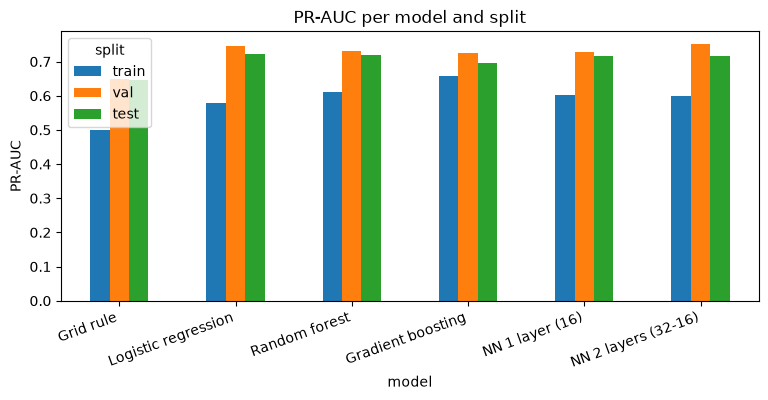

In [38]:
table.pivot(index='model', columns='split', values='pr_auc')[['train', 'val', 'test']].loc[list(p_test)].plot(kind='bar', figsize=(9, 3.5), title='PR-AUC per model and split')
plt.ylabel('PR-AUC')
plt.xticks(rotation=20, ha='right')
plt.show()

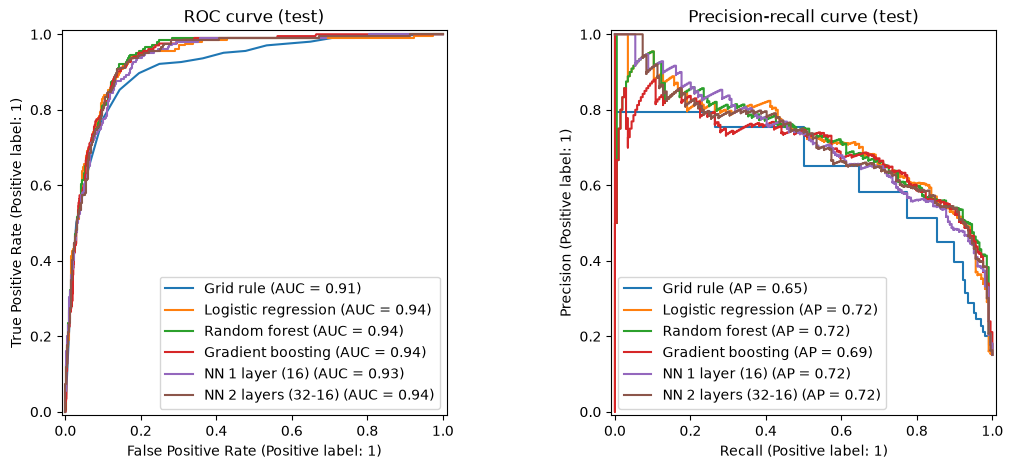

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, p in p_test.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=ax[1])
ax[0].set_title('ROC curve (test)')
ax[1].set_title('Precision-recall curve (test)')
plt.show()

**What we see**

- **Every model beats the grid rule.** On test, PR-AUC goes from 0.647 to about 0.70-0.72. The other features add real information on top of the start position.
- **The models are very close to each other.** On validation the PR-AUC runs from 0.724 to 0.751, and on test from 0.695 to 0.723. Section 6.3 showed that the seed alone moves a network by about 0.01, so we cannot call a winner among logistic regression, random forest and the networks.
- **Gradient boosting is the lowest** on PR-AUC on both validation and test, although it has the highest train score. Its closer fit to the training seasons did not carry over.
- **No overfitting in the final models:** validation and test scores are at or above the train scores.
- **Thresholds carry over well.** The F1 on test (0.66-0.69) is a bit lower than on validation (0.71-0.73), which is expected because the thresholds were tuned on validation.

**Final model: logistic regression.** We chose it from the validation column: it is tied with the best network (0.746 against 0.751, inside the seed noise), and when models are tied we take the simplest one. It trains in a second, gives the same result on every run, and its weights can be read directly. The more complex models did not earn their extra complexity on this table. The test column then confirms the choice (PR-AUC 0.723, ROC-AUC 0.936), but it was not used to make it.

**Why did the complex models not win?** The features already do the hard work: form, standings and the circuit rate are built by hand in notebook 01, so there is little left for trees or hidden layers to discover. The modern training data is also small (20 cars per race).

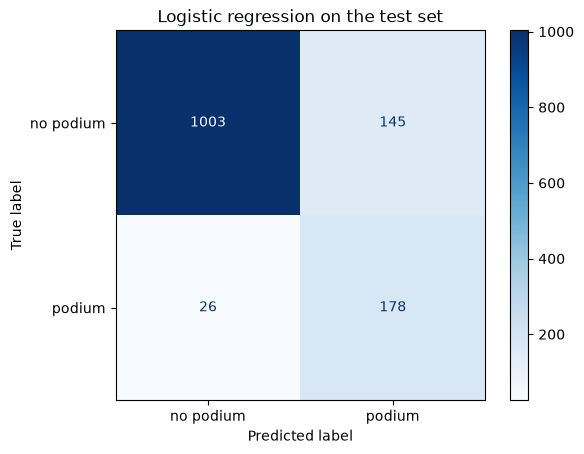

In [40]:
final_name = 'Logistic regression'
threshold = thresholds[final_name]

ConfusionMatrixDisplay.from_predictions(y_test, (p_test[final_name] >= threshold).astype(int), display_labels=['no podium', 'podium'], cmap='Blues')
plt.title('Logistic regression on the test set')
plt.show()

At the validation threshold of 0.23 the model finds 178 of the 204 test podiums (recall 0.87) and raises 145 false alarms (precision 0.55). The threshold is low because it maximises F1 with rare positives: the model names about 5 candidates per race for 3 podium places. A user who wants fewer false alarms can raise the threshold and trade recall for precision along the curve above.

## 8. Experiments

All experiments use the same recipe: change one thing, train again, compare PR-AUC with the full pipeline. We use logistic regression because it is the final model, it trains in a second, and it gives the same result on every run. The same lines are repeated in every experiment, so they go in a function.

We show validation **and** test because validation is small (117 podiums). The test column is only reported. No choice in this notebook is made from it.

In [41]:
def lr_pr_auc(X_a, y_a, X_b, X_c):
    # fit a logistic regression on X_a, return PR-AUC on validation (X_b) and test (X_c)
    m = LogisticRegression(max_iter=1000).fit(X_a, y_a)
    return [average_precision_score(y_val, m.predict_proba(X_b)[:, 1]), average_precision_score(y_test, m.predict_proba(X_c)[:, 1])]

full = lr_pr_auc(X_train_s, y_train, X_val_s, X_test_s)
full

[0.7459006979594693, 0.7232688610530509]

### 8.1 Feature-group ablation

We remove one group of features at a time, train again, and see how much PR-AUC drops. The groups are the ones from notebook 01.

In [42]:
groups = {
    'grid': ['grid_position', 'grid_position_relative', 'front_row_start'],
    'qualifying': ['grid_penalty_places', 'qualifying_gap_to_pole_percent', 'has_qualifying_data'],
    'driver form': ['driver_races_before', 'driver_podium_rate_last_5_races', 'driver_average_finish_last_5_races', 'driver_retirement_rate_last_10_races', 'driver_career_podium_rate', 'driver_podium_rate_at_circuit'],
    'constructor form': ['constructor_podium_rate_last_5_races', 'constructor_average_finish_last_5_races', 'constructor_mechanical_retirement_rate_last_10_races'],
    'standings': ['driver_points_share_before_race', 'driver_standing_position_before_race', 'driver_season_wins_before_race', 'constructor_points_share_before_race', 'constructor_standing_position_before_race'],
    'context': ['driver_age', 'home_race', 'season_progress', 'circuit_podium_rate_for_grid_group'],
}
sum(len(g) for g in groups.values())

24

All 24 features are in exactly one group. We run the ablation for logistic regression and, as a second opinion, for the random forest.

In [43]:
rf_full = average_precision_score(y_val, rf.predict_proba(X_val)[:, 1])

rows = []
for name, group in groups.items():
    keep = [f for f in features if f not in group]
    lr_scores = lr_pr_auc(X_train_s[keep], y_train, X_val_s[keep], X_test_s[keep])
    m = RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42, n_jobs=-1).fit(X_train[keep], y_train)
    rf_score = average_precision_score(y_val, m.predict_proba(X_val[keep])[:, 1])
    rows.append([name, len(keep), full[0] - lr_scores[0], full[1] - lr_scores[1], rf_full - rf_score])

ablation = pd.DataFrame(rows, columns=['removed group', 'features left', 'LR val drop', 'LR test drop', 'RF val drop']).set_index('removed group')
ablation.round(4)

,features left,LR val drop,LR test drop,RF val drop
removed group,,,,
grid,21,-0.0113,0.0215,0.0084
qualifying,21,0.0035,0.0012,0.0090
driver form,18,0.0081,-0.0016,0.0061
constructor form,21,-0.0093,0.0065,-0.0044
standings,19,0.0068,0.0089,0.0122
context,20,0.0125,0.0001,0.0084


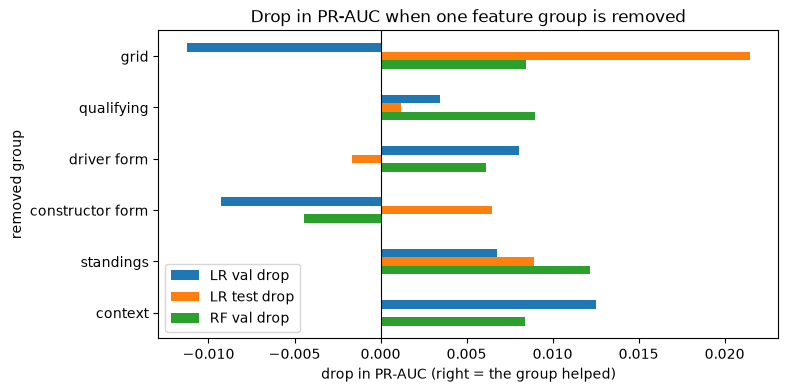

In [44]:
ablation[['LR val drop', 'LR test drop', 'RF val drop']].plot(kind='barh', figsize=(8, 4), title='Drop in PR-AUC when one feature group is removed')
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('drop in PR-AUC (right = the group helped)')
plt.gca().invert_yaxis()
plt.show()

**No single group is essential.** Every drop is below about 0.02, and several are negative (the score went up without the group). The sign also flips between validation and test: removing the grid group *helps* on validation (-0.011) and *hurts* on test (+0.022). With the noise level from section 6.3 (about 0.01), most of these bars cannot be told apart from zero.

What we can say:

- **Standings** and **qualifying** are the only groups whose removal costs something in all three columns, and even there the drop is at most 0.012.
- **Grid** gives the largest single drop (0.022 on test), but not on validation.
- The small drops do not mean the groups are useless. They overlap (section 2.2), so when one is removed the others fill in. For example, without the three grid features the model still has `circuit_podium_rate_for_grid_group`, which is built from the grid.

Removing a group shows little when another group carries the same information. So we also turn it around: train on **one group alone**.

In [45]:
rows = []
for name, group in groups.items():
    rows.append([name] + lr_pr_auc(X_train_s[group], y_train, X_val_s[group], X_test_s[group]))
rows.append(['all features'] + full)

alone = pd.DataFrame(rows, columns=['only this group', 'val_pr_auc', 'test_pr_auc']).set_index('only this group')
alone.round(4)

,val_pr_auc,test_pr_auc
only this group,,
grid,0.6552,0.6582
qualifying,0.6392,0.6065
driver form,0.6525,0.5188
constructor form,0.5340,0.5085
standings,0.6612,0.5619
context,0.6353,0.5744
all features,0.7459,0.7233


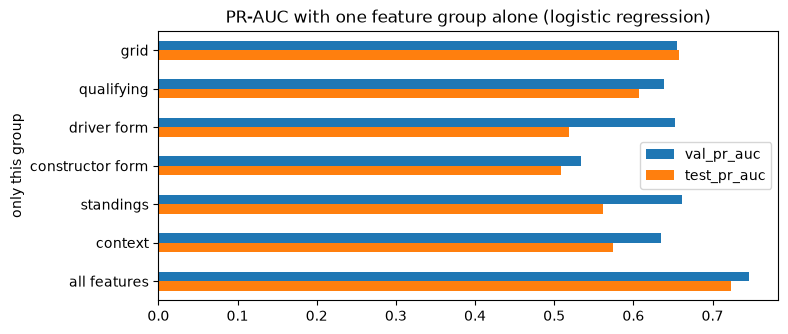

In [46]:
alone.plot(kind='barh', figsize=(8, 3.5), title='PR-AUC with one feature group alone (logistic regression)')
plt.gca().invert_yaxis()
plt.show()

This view is clearer. Every group alone is far below the full model (0.746 on validation, 0.723 on test), so **the gain comes from combining groups**, not from one of them.

- **Grid alone** is the strongest and the most stable (0.655 validation, 0.658 test), close to the grid rule.
- **Standings and driver form alone** look as good as grid on validation but fall to 0.52-0.56 on test. They describe who has been strong so far, which says less in some seasons than in others.
- **Constructor form alone** is the weakest.

Together with the ablation: grid is the core signal, and the form, standings, qualifying and context groups each add a small, overlapping part on top of it. We keep all six groups.

### 8.2 Grid position: absolute, relative, or both?

Notebook 01 kept both `grid_position` (1, 2, 3, ...) and `grid_position_relative` (grid divided by the number of starters) and left the choice to an experiment. We drop one at a time.

In [47]:
rows = [['both (our pipeline)'] + full]
for drop in ['grid_position', 'grid_position_relative']:
    keep = [f for f in features if f != drop]
    rows.append(['without ' + drop] + lr_pr_auc(X_train_s[keep], y_train, X_val_s[keep], X_test_s[keep]))

pd.DataFrame(rows, columns=['features', 'val_pr_auc', 'test_pr_auc']).round(4)

,features,val_pr_auc,test_pr_auc
0,both (our pipeline),0.7459,0.7233
1,without grid_position,0.7486,0.7233
2,without grid_position_relative,0.7464,0.7227


No difference: the three rows are within 0.003 of each other. The two columns carry the same information (correlation 0.96), so the model does not need both, and neither version is better than the other. We keep both because dropping one gives no gain, but a smaller table could drop either one.

### 8.3 Which seasons to train on?

F1 in the 1950s was a different sport: other points, shared cars, no qualifying data. Old rows give more data but may teach the model outdated patterns. We compare training on all seasons with training from 1994 and from 2003.

In [48]:
rows = []
for start in [1950, 1994, 2003]:
    mask = train['year'] >= start
    rows.append([start, mask.sum()] + lr_pr_auc(X_train_s[mask], y_train[mask], X_val_s, X_test_s))

pd.DataFrame(rows, columns=['train from', 'train rows', 'val_pr_auc', 'test_pr_auc']).round(4)

,train from,train rows,val_pr_auc,test_pr_auc
0,1950,22444,0.7459,0.7233
1,1994,10091,0.7519,0.7256
2,2003,6782,0.7493,0.7257


Training from 1994 uses less than half of the rows and scores the same or a little higher (0.752 against 0.746 on validation, 0.726 against 0.723 on test). The difference is inside the noise, so we cannot say the old seasons hurt, but they clearly **do not help**: 12,000 rows from before 1994 add nothing for predicting 2020-2024.

We keep all years in the final model, as decided in notebook 01, because the result is the same and no rows have to be thrown away. This is the era sensitivity to report as a limitation: the model is scored on modern races, and most of its training rows come from a different kind of F1.

### 8.4 Pre-processing order

Three experiments on the order of the pre-processing steps. Our pipeline is: **split → fill with the train median → scale with the train mean and std**.

#### Experiment A: split first, or pre-process first?

The wrong order is to fill and scale the whole table first and split afterwards. Then the medians, means and standard deviations are computed with the validation and test rows inside, which is a leak. First we look at how different the medians are.

In [49]:
medians_all = df[features].median()
pd.DataFrame({'train only': medians, 'all rows': medians_all})[medians != medians_all].round(3)

,train only,all rows
qualifying_gap_to_pole_percent,1.961,1.836
driver_races_before,41.000,45.000
driver_average_finish_last_5_races,12.000,11.800
constructor_average_finish_last_5_races,11.900,11.800
driver_points_share_before_race,0.047,0.051
constructor_points_share_before_race,0.114,0.116
driver_age,29.544,29.363
season_progress,0.556,0.545
circuit_podium_rate_for_grid_group,0.030,0.029


In [50]:
X_all = df[features].fillna(medians_all)
X_all_s = (X_all - X_all.mean()) / X_all.std()

a_wrong = lr_pr_auc(X_all_s[df['split'] == 'train'], y_train, X_all_s[df['split'] == 'val'], X_all_s[df['split'] == 'test'])
pd.DataFrame([['split first (our pipeline)'] + full, ['pre-process first'] + a_wrong], columns=['order', 'val_pr_auc', 'test_pr_auc']).round(4)

,order,val_pr_auc,test_pr_auc
0,split first (our pipeline),0.7459,0.7233
1,pre-process first,0.7459,0.7235


The scores are the same to three decimals. The medians barely move because the validation and test rows are only 9% of the table, and a median or a mean is one number that a few rows cannot shift much.

So here the wrong order does not buy a better score. We still split first, because it is the only order that is honest: at prediction time the future races do not exist yet, and the inference function in section 10 can only use the training values.

#### Experiment B: fill then scale, or scale then fill?

If we scale first, the mean and standard deviation are computed from the real values only. If we fill first, the filled rows are part of them. For `qualifying_gap_to_pole_percent` that is 14,284 identical values, which shrink the standard deviation.

In [51]:
mean_b = train[features].mean()   # pandas skips the missing values
std_b = train[features].std()
pd.DataFrame({'std, fill first': std, 'std, scale first': std_b}).loc[['qualifying_gap_to_pole_percent', 'driver_podium_rate_at_circuit']].round(3)

,"std, fill first","std, scale first"
qualifying_gap_to_pole_percent,1.573,2.572
driver_podium_rate_at_circuit,0.216,0.248


In [52]:
Xb_train = (train[features] - mean_b) / std_b
medians_b = Xb_train.median()

b_other = lr_pr_auc(Xb_train.fillna(medians_b), y_train, ((val[features] - mean_b) / std_b).fillna(medians_b), ((test[features] - mean_b) / std_b).fillna(medians_b))
pd.DataFrame([['fill then scale (our pipeline)'] + full, ['scale then fill'] + b_other], columns=['order', 'val_pr_auc', 'test_pr_auc']).round(4)

,order,val_pr_auc,test_pr_auc
0,fill then scale (our pipeline),0.7459,0.7233
1,scale then fill,0.7461,0.7236


The standard deviation of the qualifying gap is very different between the two orders (1.57 against 2.57), but the scores are the same. For a logistic regression both orders give the same filled column, only stretched by a different constant, and the model absorbs that in the weight.

The order would matter for a method that fills from other columns (like nearest neighbours) or for a model that is sensitive to the exact scale. We keep fill then scale, because then the scaled table has exactly mean 0 and standard deviation 1.

#### Experiment C: "was missing" flags before or after filling?

A flag column says "this value was missing". It only works if it is made **before** filling. After filling there is nothing left to flag:

In [53]:
flag_cols = ['qualifying_gap_to_pole_percent', 'driver_podium_rate_at_circuit', 'driver_standing_position_before_race']

print('flags made after filling: ', X_train[flag_cols].isna().sum().sum(), 'cells flagged')
print('flags made before filling:', train[flag_cols].isna().sum().sum(), 'cells flagged')

flags made after filling:  0 cells flagged
flags made before filling: 24120 cells flagged


Flags made after filling would be all 0, which is the same as our pipeline without flags. So we compare our pipeline with flags made before filling, for the three features with the most missing values.

In [54]:
Xc_train = X_train_s.copy()
Xc_val = X_val_s.copy()
Xc_test = X_test_s.copy()
for c in flag_cols:
    Xc_train[c + '_missing'] = train[c].isna().astype(int)
    Xc_val[c + '_missing'] = val[c].isna().astype(int)
    Xc_test[c + '_missing'] = test[c].isna().astype(int)

c_flags = lr_pr_auc(Xc_train, y_train, Xc_val, Xc_test)
pd.DataFrame([['no flags / flags after filling (our pipeline)'] + full, ['flags before filling'] + c_flags], columns=['order', 'val_pr_auc', 'test_pr_auc']).round(4)

,order,val_pr_auc,test_pr_auc
0,no flags / flags after filling (our pipeline),0.7459,0.7233
1,flags before filling,0.7446,0.7213


Here the order decides whether the step works at all: after filling, 0 cells can be flagged, before filling 24,120.

The flags themselves do not help: PR-AUC is slightly lower with them (0.745 against 0.746 on validation), again inside the noise. `has_qualifying_data` already covers the biggest case, and a missing circuit history or standings position says little about the podium. We keep the pipeline without extra flags.

**Summary of the three experiments:** the pre-processing order changes the numbers inside the table (medians, standard deviations, flags) but not the score of this model. We keep split → fill → scale because it is leak-free and is the order the inference function can repeat.

## 9. Explainability

We explain the final model, the logistic regression.

**Important:** everything in this section describes **what the model relies on**, not what causes a podium. A high importance for a feature means the predictions change a lot when that feature changes. It does not prove that changing it in the real world would change the result. For example, the model leans on the grid position, but a slow car moved to pole by hand would not become a podium car.

### 9.1 Global: permutation importance

We shuffle one feature in the validation set, which breaks its link with the target, and measure how much PR-AUC drops. A big drop means the model needs that feature. Each feature is shuffled 10 times.

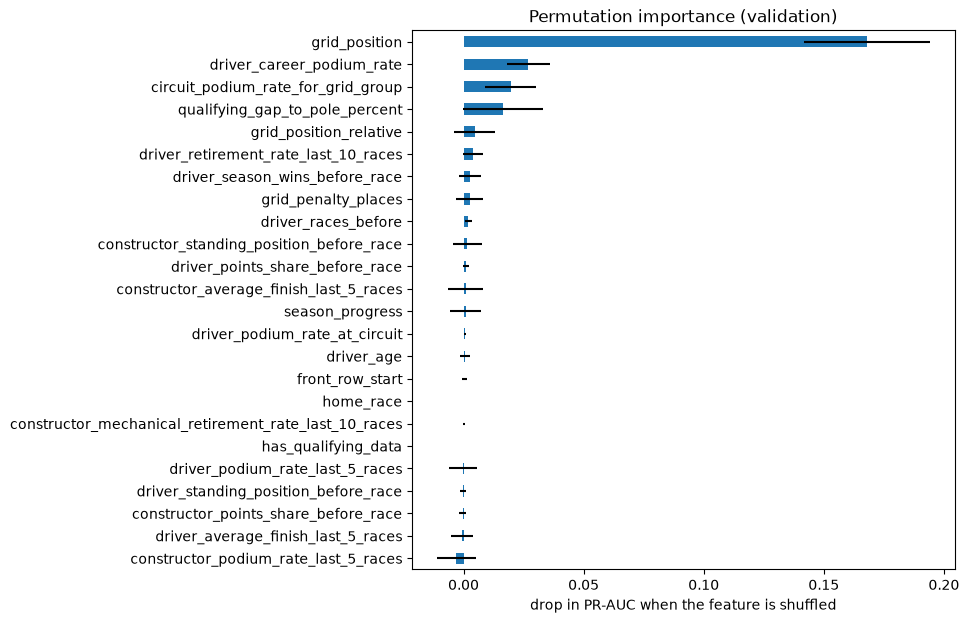

In [55]:
perm = permutation_importance(lr, X_val_s, y_val, scoring='average_precision', n_repeats=10, random_state=42)

perm_table = pd.DataFrame({'drop in PR-AUC': perm.importances_mean, 'std': perm.importances_std}, index=features).sort_values('drop in PR-AUC')
perm_table['drop in PR-AUC'].plot(kind='barh', xerr=perm_table['std'], figsize=(7, 7), title='Permutation importance (validation)')
plt.xlabel('drop in PR-AUC when the feature is shuffled')
plt.show()

`grid_position` stands far above everything else: shuffling it costs about 0.17 PR-AUC. Then come `driver_career_podium_rate`, `circuit_podium_rate_for_grid_group` and `qualifying_gap_to_pole_percent`, each around 0.02. Most other features are at zero, and the black lines (the spread over the 10 shuffles) cross zero.

A feature at zero is not proven useless. When two features carry the same information (driver and constructor form, the two grid columns), shuffling one leaves the other to do the job, so both look small. This matches the ablation.

### 9.2 Global: SHAP

SHAP splits each prediction into one contribution per feature. A positive value pushed this prediction towards podium, a negative value pushed it away. The contributions of a row add up to the model's output for that row (in log-odds, the scale the logistic regression works in).

We compute the values for every validation row.

In [56]:
explainer = shap.LinearExplainer(lr, X_train_s)
shap_values = explainer(X_val_s)
shap_values.data = X_val.values   # show the real values in the plots, not the scaled ones

shap_values.shape

Background dataset has 22444 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=22444 when initializing the masker.


(775, 24)

The mean size of the contributions gives a global ranking.

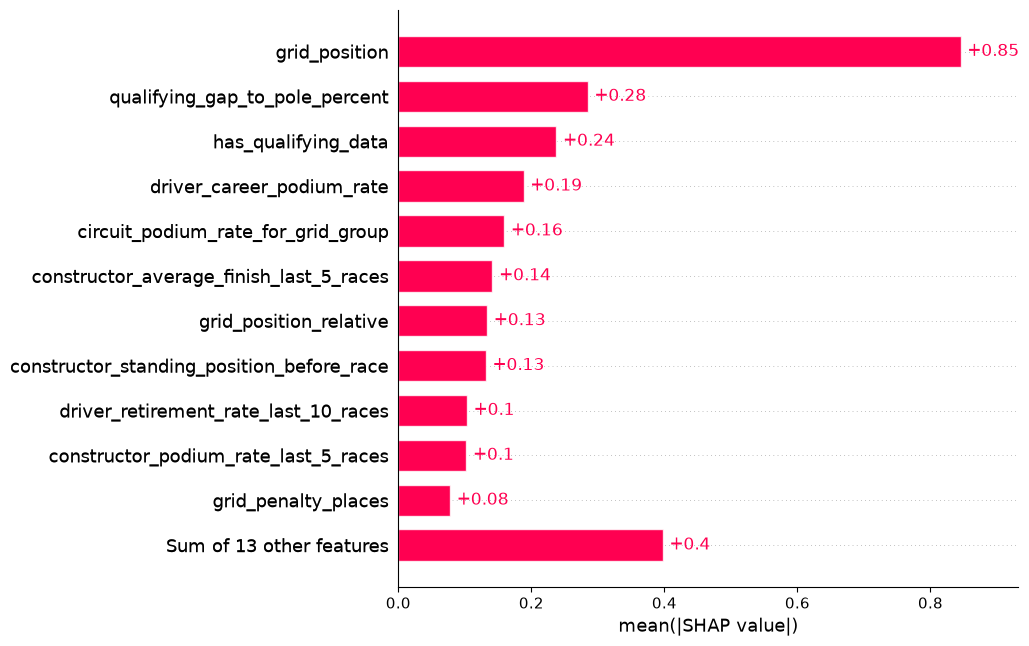

In [57]:
shap.plots.bar(shap_values, max_display=12)

The beeswarm plot shows every validation row as a dot. Red = high value of the feature, blue = low value.

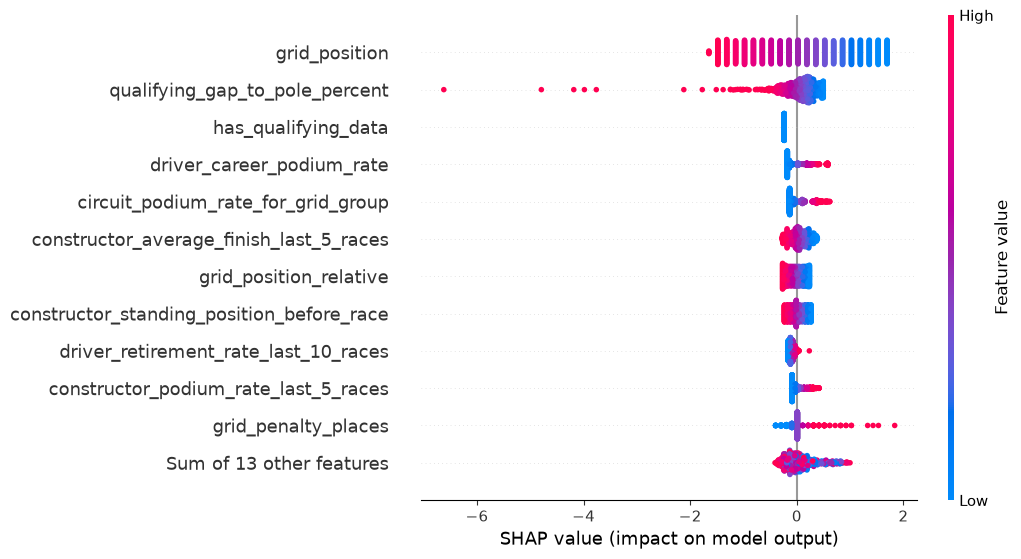

In [58]:
shap.plots.beeswarm(shap_values, max_display=12)

SHAP agrees with permutation importance on the top: `grid_position` has by far the largest contributions, followed by the qualifying gap, the career podium rate and the circuit rate.

Reading the beeswarm:

- `grid_position`: red dots (a start far back) are on the left, blue dots (a start at the front) on the right. The model lowers the podium probability as the grid number grows.
- `qualifying_gap_to_pole_percent`: a few red dots sit very far left. These are drivers with a huge gap to pole. A linear model keeps subtracting for every extra percent, so outliers get extreme values. This is a limit of the model.
- `grid_penalty_places`: red dots on the right. A driver who starts further back than he qualified is faster than his grid slot suggests, and the model gives some of that back.
- `has_qualifying_data` ranks third in the bar plot but is a single blue column: every validation race has qualifying data, so it gives the **same** shift to every row and cannot change the order of the drivers. This is why permutation importance shows it at zero. SHAP measures how far a feature moves the output from the training average, permutation importance measures how much the ranking needs it.

Again: these plots show how **the model** uses the features. They are not effects on the race.

### 9.3 Local: one prediction

We take one row: the driver on pole in the last validation race.

In [59]:
i = np.where((val['raceId'] == val['raceId'].iloc[-1]) & (val['grid_position'] == 1))[0][0]

print('predicted probability:', round(lr.predict_proba(X_val_s.iloc[[i]])[0, 1], 3), '| real podium:', y_val.iloc[i])
val.iloc[i][['raceId', 'driverId', 'year', 'round', 'grid_position', 'driver_podium_rate_last_5_races', 'constructor_podium_rate_last_5_races', 'driver_points_share_before_race']]

predicted probability: 0.852 | real podium: 1


raceId                                  1073
driverId                                 830
year                                    2021
round                                     22
grid_position                              1
driver_podium_rate_last_5_races          1.0
constructor_podium_rate_last_5_races     0.7
driver_points_share_before_race          1.0
Name: 23200, dtype: object

**Local SHAP (waterfall).** It starts from the average output of the model at the bottom and adds the contribution of each feature until it reaches the output for this row at the top.

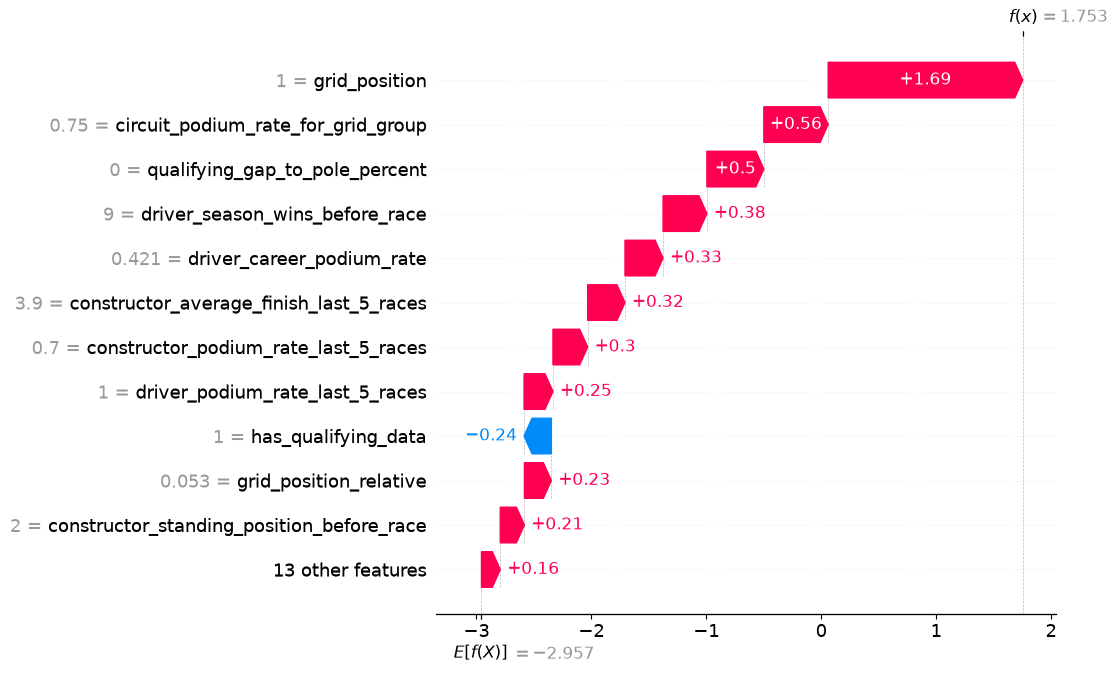

In [60]:
shap.plots.waterfall(shap_values[i], max_display=12)

**LIME.** LIME makes many small random changes to this row, asks the model for a prediction on each, and fits a small linear model on those to see which features matter around this one row.

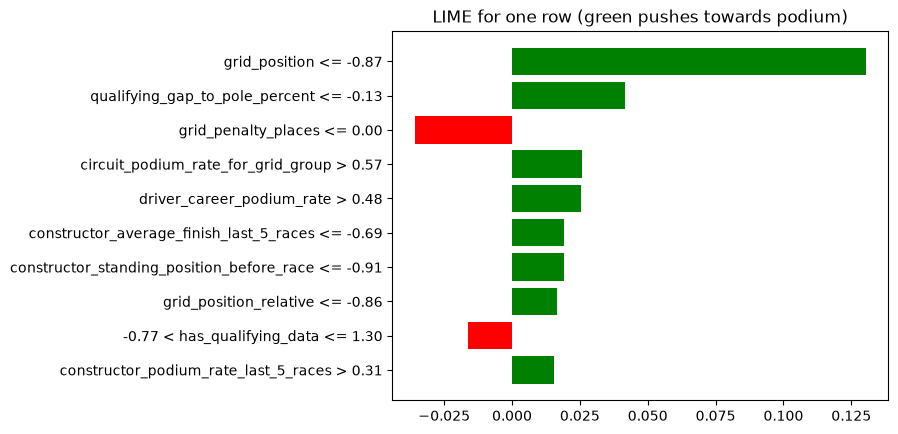

In [61]:
lime_explainer = LimeTabularExplainer(X_train_s.values, feature_names=features, class_names=['no podium', 'podium'], mode='classification', random_state=42)
lime_exp = lime_explainer.explain_instance(X_val_s.iloc[i].values, lambda a: lr.predict_proba(pd.DataFrame(a, columns=features)), num_features=10)

lime_exp.as_pyplot_figure()
plt.title('LIME for one row (green pushes towards podium)')
plt.show()

The row is the pole sitter of the 2021 season finale (round 22). The model gives 0.85 and he did finish on the podium.

- **SHAP:** the model starts from its average output (-2.96 in log-odds, a probability of about 5%) and ends at +1.75 (about 85%). The start from pole adds the most (+1.69). The circuit's podium rate for the front of the grid (0.75), the zero gap to pole, 9 wins this season, his career podium rate and the team's recent results all push up. Only `has_qualifying_data` pushes down, and it does so for every row (see above).
- **LIME** gives the same picture with a different method: the grid position is the longest green bar, then the gap to pole, the circuit rate and the career podium rate. The conditions are in scaled units because the model works on the scaled table (`grid_position <= -0.87` means a start near the front).

The two methods agree on which features drive this prediction, which makes the explanation more trustworthy. Both explain why the model said 0.85. Neither says that these features caused the podium.

## 10. Inference function

One function that takes the pre-race features of one driver in one race and returns the podium probability and the yes/no decision. It repeats the training pipeline with the values learned from train: fill with `medians`, scale with `mean` and `std`, predict with the final model, and compare with the validation `threshold`.

A feature that is not in the record is treated as missing.

In [62]:
def predict_podium(record):
    row = pd.DataFrame([record], columns=features).astype(float)   # features not in the record become NaN
    row = row.fillna(medians)
    row = (row - mean) / std
    p = lr.predict_proba(row)[0, 1]
    return round(float(p), 3), int(p >= threshold)

**A complete record.** We take a test row that has every feature.

In [63]:
record = test.dropna()[features].iloc[0].to_dict()
record

{'grid_position': 4.0,
 'grid_position_relative': 0.2105263157894736,
 'front_row_start': 0.0,
 'grid_penalty_places': 0.0,
 'qualifying_gap_to_pole_percent': 0.2959183673469256,
 'has_qualifying_data': 1.0,
 'driver_races_before': 142.0,
 'driver_podium_rate_last_5_races': 0.8,
 'driver_average_finish_last_5_races': 5.2,
 'driver_retirement_rate_last_10_races': 0.2,
 'driver_career_podium_rate': 0.4225352112676056,
 'driver_podium_rate_at_circuit': 1.0,
 'constructor_podium_rate_last_5_races': 0.4,
 'constructor_average_finish_last_5_races': 8.4,
 'constructor_mechanical_retirement_rate_last_10_races': 0.15,
 'driver_points_share_before_race': 0.0,
 'driver_standing_position_before_race': 19.0,
 'driver_season_wins_before_race': 0.0,
 'constructor_points_share_before_race': 0.0,
 'constructor_standing_position_before_race': 10.0,
 'driver_age': 24.487337440109517,
 'home_race': 0.0,
 'season_progress': 0.0909090909090909,
 'circuit_podium_rate_for_grid_group': 0.26336}

In [64]:
predict_podium(record)

(0.358, 1)

**A partially-missing record.** The same driver, but we do not know the qualifying gap, the history at this circuit or the standings position.

In [65]:
partial = record.copy()
del partial['qualifying_gap_to_pole_percent']
del partial['driver_podium_rate_at_circuit']
partial['driver_standing_position_before_race'] = None

predict_podium(partial)

(0.276, 1)

The function works on both records. With the three values missing it fills in the train medians and the probability moves from 0.36 to 0.28, still above the threshold of 0.23.

The filled values are "typical" values, not the real ones, so a prediction from a partial record is less reliable. Here the driver had a podium rate of 1.0 at this circuit, and the median that replaced it is much lower, which is why the probability dropped.